# 07 · Current regime and the switch-on triggers (plan: "Strategy for the sector now")

> **Descriptive only, spot proxy.**
> - This notebook reports the state of the pre-registered rules on the latest spot data. It is not a trade recommendation. I'm not a financial advisor, and this is an educational research framework.
> - On the spot proxy, all three spreads **fail** the pre-registered gates (notebook 06), so none is cleared to trade, whatever the triggers below say.

**The plan's strategy:** build and paper-trade the engine while the regime is extreme, and switch on normalisation trades only when the filter turns.

**Switch-on triggers**
- **HO−RB and the 3-2-1 crack:** all three must hold:
  - P(revert) ≥ 0.6
  - the relevant crack's GARCH volatility back under its 80th percentile (the diesel crack HO − CL for HO−RB; the 3-2-1 itself for the crack)
  - no Hormuz re-closure for 4 weeks
- **Brent–WTI:** the *futures* spread at |z| ≥ 2 with the filter on. Spot is ignored while Dated Brent is dislocated.

**How "80th percentile" is measured:** against the full point-in-time history of the volatility forecast since 2010, i.e. "back to normal". This choice is recorded in `src/oilrv/readout.py`.

In [1]:
import json
import pandas as pd
from IPython.display import Image
from oilrv.config import ROOT
import sys; sys.path.insert(0, str(ROOT / 'scripts'))
import run_readout
summary = run_readout.main(today='2026-10-24')
T, F = ROOT / 'output/tables', ROOT / 'output/figures'
read = lambda n, **k: pd.read_csv(T / n, **k)
pd.set_option('display.width', 200)
{k: summary[k] for k in ['data_as_of', 'today', 'last_hormuz_closure', 'days_since_hormuz_closure_today', 'diesel_crack', 'spot_proxy_gate_verdicts']}

{'data_as_of': '2026-10-20',
 'today': '2026-10-24',
 'last_hormuz_closure': '2026-09-27',
 'days_since_hormuz_closure_today': 27.0,
 'diesel_crack': {'level': 113.24,
  'sigma_next': 8.033875720624271,
  'sigma_pct_history': 0.9904668785138108},
 'spot_proxy_gate_verdicts': {'fixed|crack321': False,
  'fixed|brent_wti': False,
  'fixed|ho_rb': False}}

## State of each spread under the gated rules (last close in the data: 20 Oct 2026)

In [2]:
read('07_state.csv', index_col=0).T

,fixed|crack321,fixed|brent_wti,fixed|ho_rb,johansen|crack321
as_of,2026-10-20,2026-10-20,2026-10-20,2026-10-20
S,46.936,7.33,99.456,-51.668256
z,1.758001,0.550773,6.179545,-6.892051
sigma_next,5.21726,1.541046,7.732159,5.21525
sigma_pct_history,0.992911,0.781716,0.986067,0.993206
half_life,64.915911,10.347354,34.471236,6.160721
adf_p,0.98041,0.046135,0.586169,0.000047
gate_open,True,True,True,True
p_revert,0.140956,0.503846,0.383113,0.312148
armed,True,True,True,True


- **3-2-1 crack:** z ≈ 1.8, below the entry band. The collapsing gasoline crack pulled it down from about 4 in September.
  - GARCH σ̂ is \$5.2/bbl a day, in the 99th percentile of its history.
  - Even a 2σ signal today would size to **0 contracts**: the volatility limit is 0.38 units. This is the plan's worked example B, with an actual σ̂ about twice the \$2.50 the example assumed.
  - P(revert) = 0.14.
- **Brent–WTI:** z ≈ 0.6, so there is no signal. P = 0.50. A 2σ entry today would size to 3 units: the volatility limit is 3.9, the stop limit 4.9, and the cap is 3. The trigger needs futures data in any case.
- **HO−RB:** z ≈ 6.2, beyond the |z| = 4 stop, so no entry is allowed.
  - P = 0.38 is already below the 0.4 exit level.
  - σ̂ is \$7.7/bbl a day (99th percentile).
  - The volatility limit is 0.78 units, so integer size is 0.
- **No spread is in a trade or has an entry pending.**

## Switch-on triggers

In [3]:
read('07_triggers.csv', index_col=0).T

,fixed|crack321,fixed|brent_wti,fixed|ho_rb
P(revert) >= 0.6,False,False,False
vol percentile < 80%,False,NaN,False
no Hormuz closure for 28 days,False,NaN,False
ALL MET,False,False,False
vol series,crack321,brent_wti,diesel crack (HO − CL)
vol percentile,0.993,0.782,0.99
futures data (not spot),NaN,False,NaN
|z| >= 2.0,NaN,False,NaN


- **No trigger set is met. Each spread is blocked by:**
  - Crack: P too low (0.14), volatility in the 99th percentile, and the last Hormuz closure 27 days ago.
  - HO−RB: P too low (0.38), diesel-crack volatility in the 99th percentile, and the same 27 days.
  - Brent–WTI: spot data only, z only 0.6, and P 0.50.
- **Hormuz.** The last logged closure was 27 Sep 2026, when the IRGC closed the strait to unauthorised access. The 4-week condition clears on 25 Oct 2026 if nothing new happens. The 7 Oct statements about closing "illegal" routes are not logged as a closure.
- **Volatility is the binding constraint for both cracks.** Even if P turned, sizing would give 0 contracts until σ̂ fell back by about two-thirds (crack) or a quarter (HO−RB).

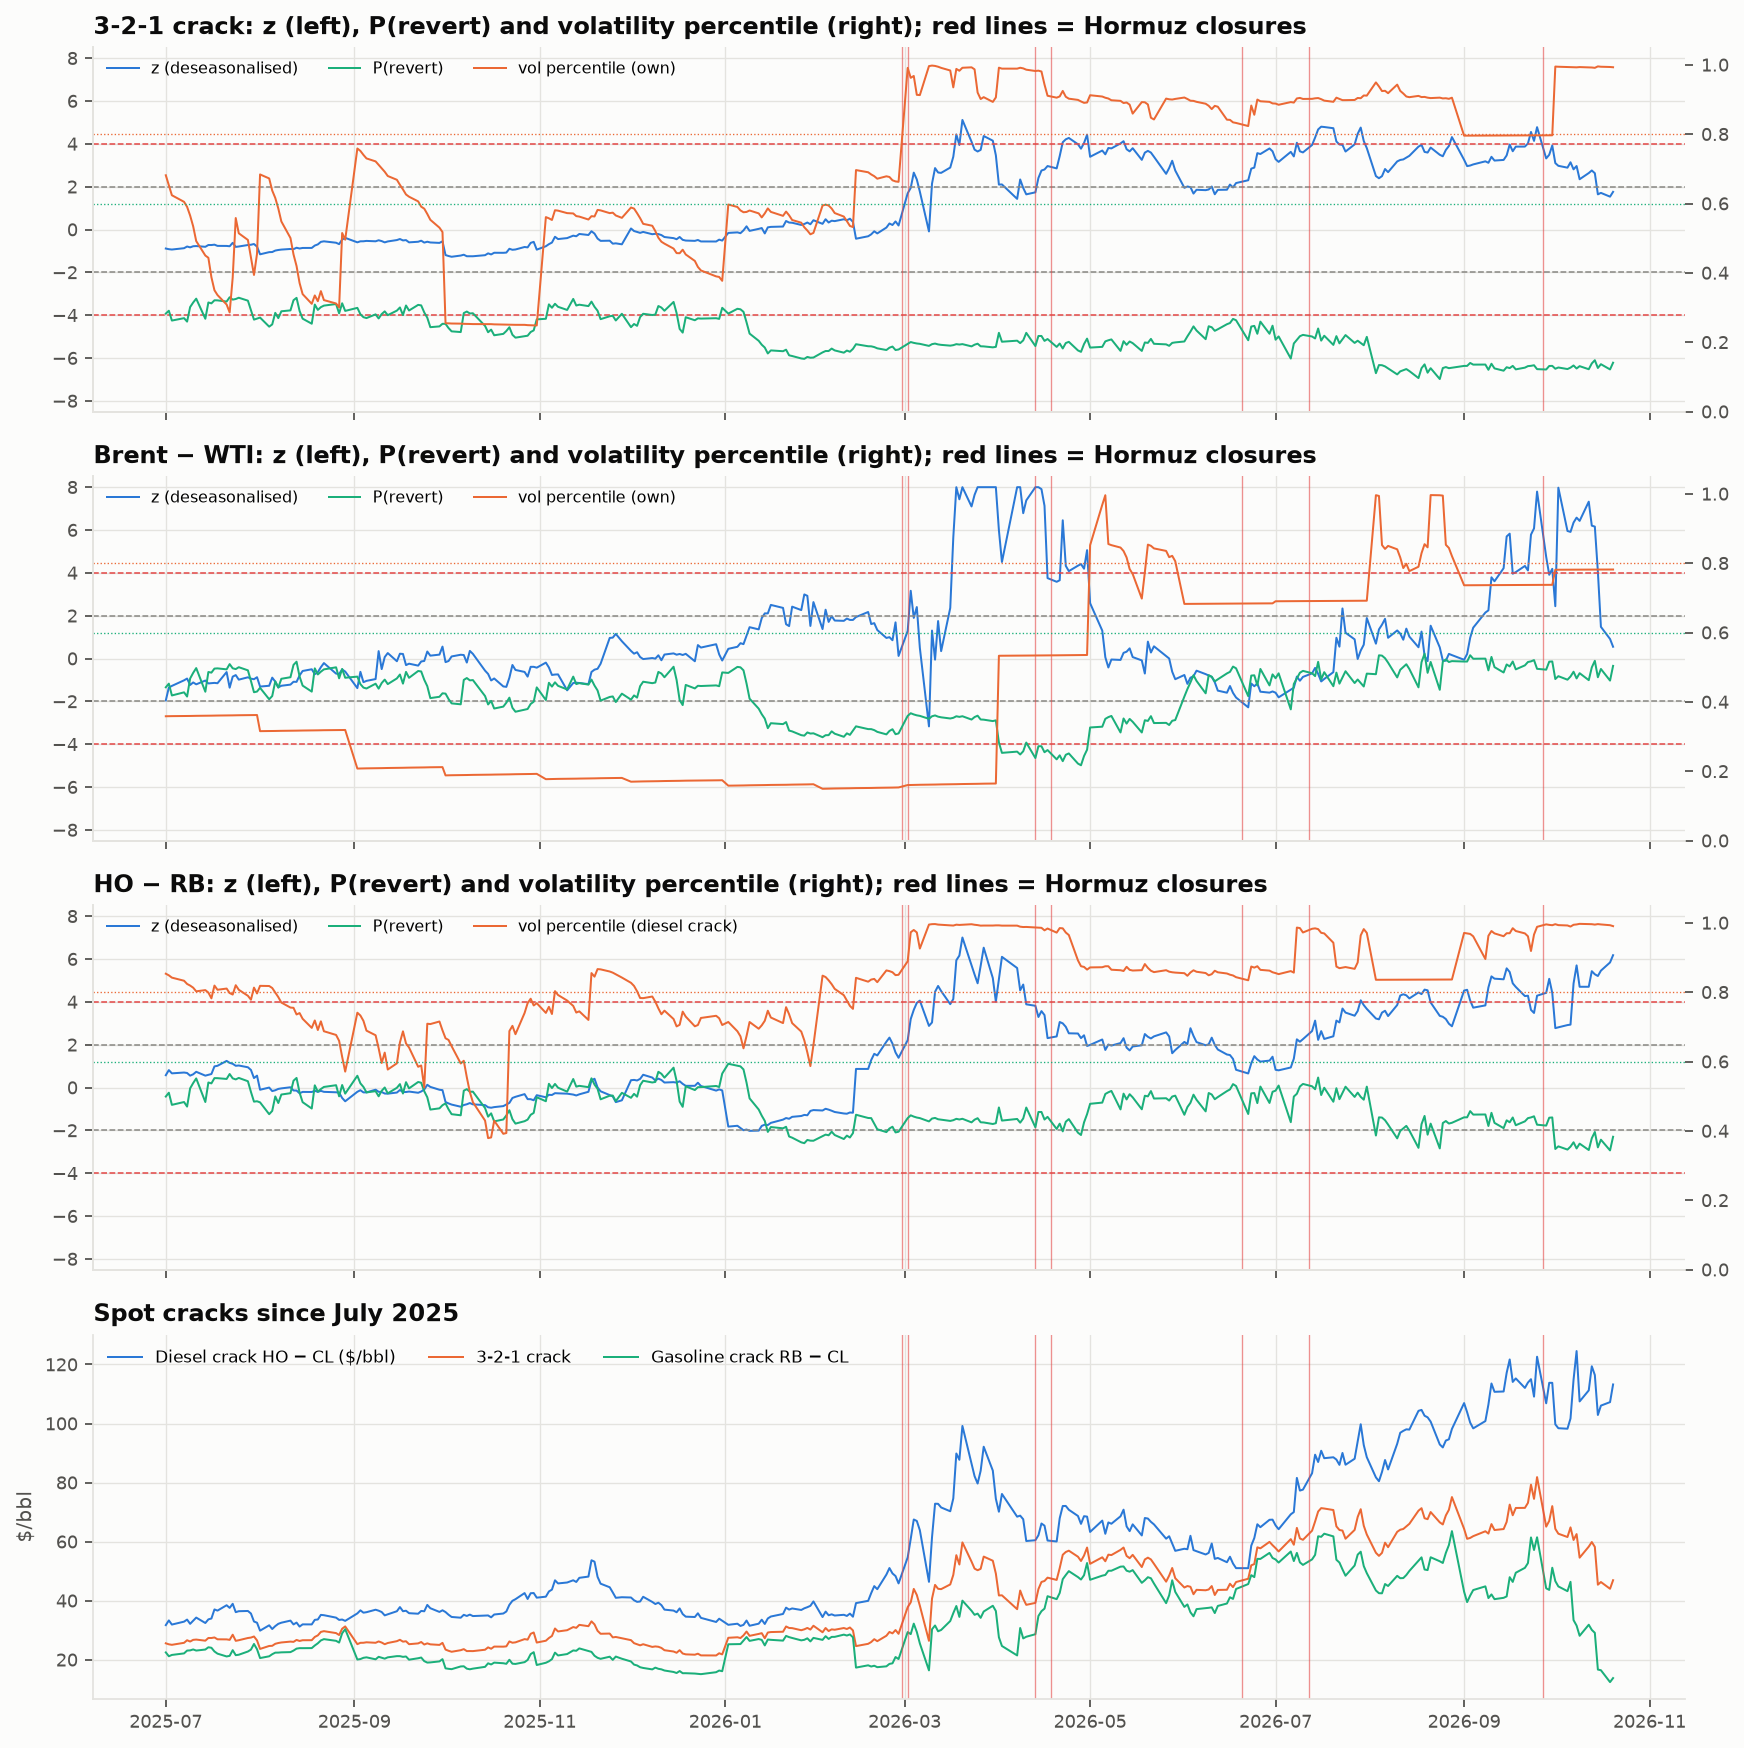

In [4]:
Image(str(F / '07_current_regime.png'))

**The diesel premium is the dislocation.**
- **The diesel crack (HO − CL) is \$113/bbl, while the gasoline crack has fallen to about \$14.** HO−RB is therefore at a record z of about 6.
- **This is where the plan's "diesel first" candidate trade would sit:** sell HO, buy RB in Q1–Q2 2027 months.
- **Under the pre-registered rules it is not tradeable now:**
  - z is past the stop.
  - The volatility trigger is far from met.
  - The rules also failed the spot-proxy backtest.
- **What the backtest says about such trades:** without the filter, HO−RB was the only spread with a positive edge (Sharpe about 0.3, t ≈ 1.3). With the filter, it sat out a profitable 2026 move. Both facts go into the report. Neither supports switching on now.

## Dates to watch (next ~4 months)

In [5]:
read('07_watch_list.csv')

,date,item,source
0,2026-10-28,EIA Weekly Petroleum Status Report (refresh in...,EIA schedule (Wednesday 10:30 ET; Thursday aft...
1,2026-11-01,OPEC: Seven-country meeting,https://www.forexfactory.com/news/1429804-opec...
2,2026-11-01,US clocks change: NYMEX settle moves to 3:30 a...,oil-rv-plan.md (Step 10)
3,2026-11-04,EIA Weekly Petroleum Status Report (refresh in...,EIA schedule (Wednesday 10:30 ET; Thursday aft...
4,2026-11-10,Next EIA Short-Term Energy Outlook,https://www.eia.gov/outlooks/steo/data.php (vi...
5,2026-11-12,EIA Weekly Petroleum Status Report (refresh in...,EIA schedule (Wednesday 10:30 ET; Thursday aft...
6,2026-11-18,EIA Weekly Petroleum Status Report (refresh in...,EIA schedule (Wednesday 10:30 ET; Thursday aft...
7,2026-11-30,End of the Atlantic hurricane season,NOAA convention (oil-rv-plan.md)
8,2027-02-26,G7 100 mb stock release expected to run throug...,https://www.hellenicshippingnews.com/?p=115055...


- **OPEC+ seven-country meeting, 1 Nov:** a scheduled blackout event. No new entries on the trading day before it (Friday 30 Oct).
- **The weekly EIA report** refreshes the inventory feature. The 11 Nov Veterans Day holiday moves that week's release to Thursday 12 Nov.
- **US clocks change, 1 Nov:** the Step 10 routine shifts by an hour in Singapore. The NYMEX settle moves to 3:30 am SGT and the US open to 10:30 pm SGT.
- **Next STEO, 10 Nov.** **End of hurricane season, 30 Nov:** the hurricane-season feature and landfall blackouts switch off until June.
- **The G7 diesel-heavy stock release** is expected to run through February 2027.

**What would change this readout**
- **The binding run:** the Bloomberg export, to rerun Parts 1–6 on futures. It might find a different edge.
- **Trigger conditions:** volatility falling back below the 80th percentile, with no new Hormuz closure for 4 weeks.
- **The filter:** a P(revert) at or above 0.6. That has been rare for every spread since 2015.